# Data Warehousing and Mining (DWM) — Experiment 05
## Experiment Title: Decision Tree Classification and Mutual Information
**Dataset:** `stock_market_data.csv` (3 Years of Daily NSE Trading Data across 20 Major Indian Stocks)

### 1. Objectives & Problem Formulation
- **Objective:** Implement **Decision Tree Classification** using **Entropy (Information Gain)** on the stock market dataset to classify daily return performance into three discrete categories (`Low`, `Medium`, `High`), and compute **Mutual Information** to evaluate attribute relevance.
- **Adaptation Note:**
  - Continuous `Daily_Return` is discretized into balanced **quantile tertiles** ($\frac{1}{3}$ and $\frac{2}{3}$ quantiles):
    - **`Low` (Bearish):** $\text{Daily\_Return} \le q_1$
    - **`Medium` (Neutral):** $q_1 < \text{Daily\_Return} \le q_2$
    - **`High` (Bullish):** $\text{Daily\_Return} > q_2$
  - To prevent target leakage, `Daily_Return` (and `Close_Price` / `High_Price` / `Low_Price` directly relative to `Open_Price` direction) is excluded from the input feature matrix $X$.
  - **Input Features ($X$):** `['Open_Price', 'Volume', 'Intraday_Volatility', 'Month']`.

---
### 2. Library Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.feature_selection import mutual_info_classif

# Set seaborn styling
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12

print("All required libraries imported successfully.")

All required libraries imported successfully.


---
### 3. Dataset Ingestion & Preprocessing
- Load `stock_market_data.csv`.
- Convert `Date` to `datetime` and extract `Month`.
- Derive `Intraday_Volatility` as $\frac{\text{High\_Price} - \text{Low\_Price}}{\text{Open\_Price}} \times 100$.
- Compute quantile tertiles ($q_1 = \frac{1}{3}$, $q_2 = \frac{2}{3}$) on `Daily_Return` and create the target column `Return_Category` (`Low`, `Medium`, `High`).

In [2]:
df = pd.read_csv('stock_market_data.csv')

# Ensure Date is datetime and extract Month
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month

# Derive Intraday_Volatility (%)
df['Intraday_Volatility'] = (((df['High_Price'] - df['Low_Price']) / df['Open_Price']) * 100).round(2)

# Compute quantile tertiles (1/3 and 2/3) on Daily_Return
q1 = df['Daily_Return'].quantile(1/3)
q2 = df['Daily_Return'].quantile(2/3)

def categorize_return(val):
    if val <= q1:
        return 'Low'
    elif val <= q2:
        return 'Medium'
    else:
        return 'High'

df['Return_Category'] = df['Daily_Return'].apply(categorize_return)

print(f"Quantile Tertile Thresholds on Daily_Return:")
print(f"  - 1/3 Quantile (q1): {q1:.4f}%  (Low  <= {q1:.4f}%)")
print(f"  - 2/3 Quantile (q2): {q2:.4f}%  ({q1:.4f}% < Medium <= {q2:.4f}%, High > {q2:.4f}%)")
print(f"\nCleaned Dataset Shape: {df.shape}")
display(df[['Date', 'Ticker', 'Open_Price', 'Volume', 'Intraday_Volatility', 'Month', 'Daily_Return', 'Return_Category']].head())

Quantile Tertile Thresholds on Daily_Return:
  - 1/3 Quantile (q1): -0.5400%  (Low  <= -0.5400%)
  - 2/3 Quantile (q2): 0.3900%  (-0.5400% < Medium <= 0.3900%, High > 0.3900%)

Cleaned Dataset Shape: (14800, 13)


,Date,Ticker,Open_Price,Volume,Intraday_Volatility,Month,Daily_Return,Return_Category
0,2023-10-12,BAJAJ-AUTO,4851.06,472168,1.96,10,0.42,High
1,2023-10-12,BRITANNIA,4391.48,518582,1.32,10,-0.46,Medium
2,2023-10-12,HCLTECH,1106.03,3921609,2.68,10,-1.71,Low
3,2023-10-12,HDFCBANK,735.43,22025336,1.33,10,0.90,High
4,2023-10-12,HINDUNILVR,2413.48,1625010,1.11,10,0.08,Medium


---
### 4. Class Distribution Analysis
Inspect the sample counts across `Low`, `Medium`, and `High` return categories and visualize the class balance.

Class Distribution of Return_Category:


,Return_Category,Count,Percentage (%)
0,Low,4964,33.54
1,Medium,4942,33.39
2,High,4894,33.07


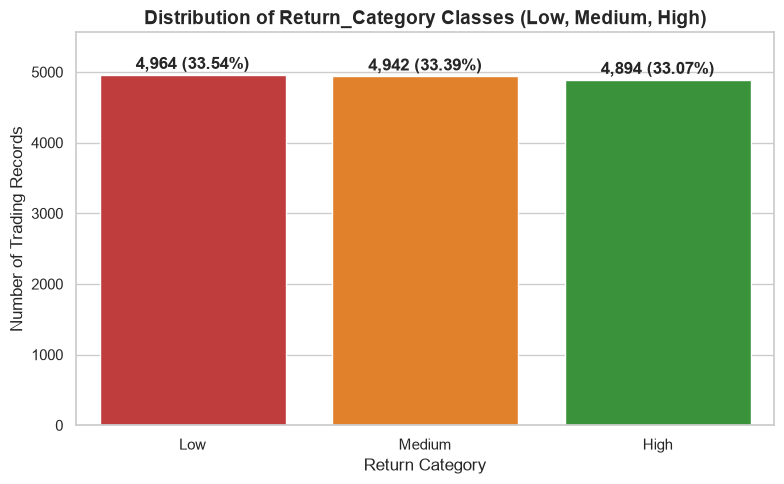

In [3]:
class_order = ['Low', 'Medium', 'High']
class_counts = df['Return_Category'].value_counts().reindex(class_order)
class_df = pd.DataFrame({
    'Return_Category': class_counts.index,
    'Count': class_counts.values,
    'Percentage (%)': (class_counts.values / len(df) * 100).round(2)
})

print("Class Distribution of Return_Category:")
display(class_df)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=class_df,
    x='Return_Category',
    y='Count',
    hue='Return_Category',
    palette=['#d62728', '#ff7f0e', '#2ca02c'],
    legend=False
)
for i, v in enumerate(class_df['Count']):
    ax.text(i, v + 80, f"{v:,} ({class_df['Percentage (%)'].iloc[i]}%)", ha='center', fontweight='bold')
plt.ylim(0, max(class_df['Count']) * 1.12)
plt.title('Distribution of Return_Category Classes (Low, Medium, High)')
plt.xlabel('Return Category')
plt.ylabel('Number of Trading Records')
plt.tight_layout()
plt.show()

---
### 5. Prepare Training and Testing Sets
- **Feature Matrix ($X$):** `['Open_Price', 'Volume', 'Intraday_Volatility', 'Month']`
- **Target Vector ($y$):** `Return_Category`
- **Stratified Split:** 80% Training / 20% Testing (`test_size=0.2, stratify=y, random_state=42`)

In [4]:
feature_cols = ['Open_Price', 'Volume', 'Intraday_Volatility', 'Month']
X = df[feature_cols]
y = df['Return_Category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Total Samples:    {len(df):,}")
print(f"Training Samples: {len(X_train):,} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing Samples:  {len(X_test):,} ({len(X_test)/len(df)*100:.1f}%)")
print("\nTraining Set Class Counts:")
print(y_train.value_counts().reindex(['Low', 'Medium', 'High']))
print("\nTesting Set Class Counts:")
print(y_test.value_counts().reindex(['Low', 'Medium', 'High']))

Total Samples:    14,800
Training Samples: 11,840 (80.0%)
Testing Samples:  2,960 (20.0%)

Training Set Class Counts:
Return_Category
Low       3971
Medium    3954
High      3915
Name: count, dtype: int64

Testing Set Class Counts:
Return_Category
Low       993
Medium    988
High      979
Name: count, dtype: int64


---
### 6. Train Decision Tree Classifier
Instantiate and train `DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42)` on the training dataset, and generate predictions on the test dataset.

In [5]:
dt_classifier = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    random_state=42
)

dt_classifier.fit(X_train, y_train)
y_pred = dt_classifier.predict(X_test)

print("Decision Tree Classifier trained successfully.")
print(f"Criterion:      {dt_classifier.criterion}")
print(f"Max Tree Depth: {dt_classifier.get_depth()}")
print(f"Number of Leaf Nodes: {dt_classifier.get_n_leaves()}")

Decision Tree Classifier trained successfully.
Criterion:      entropy
Max Tree Depth: 5
Number of Leaf Nodes: 31


---
### 7. Model Evaluation
Evaluate the Decision Tree Classifier using Test Accuracy, full `classification_report` (Precision, Recall, F1-Score, Support), and the Confusion Matrix for `['Low', 'Medium', 'High']`.

In [6]:
acc = accuracy_score(y_test, y_pred)
print(f"Decision Tree Test Accuracy: {acc:.4f} ({acc*100:.2f}%)\n")

print("=== Classification Report ===")
print(classification_report(y_test, y_pred, labels=['Low', 'Medium', 'High'], digits=4))

cm = confusion_matrix(y_test, y_pred, labels=['Low', 'Medium', 'High'])
cm_df = pd.DataFrame(
    cm,
    index=['Actual: Low', 'Actual: Medium', 'Actual: High'],
    columns=['Pred: Low', 'Pred: Medium', 'Pred: High']
)
print("=== Confusion Matrix Table ===")
display(cm_df)

Decision Tree Test Accuracy: 0.4838 (48.38%)

=== Classification Report ===
              precision    recall  f1-score   support

         Low     0.4148    0.3776    0.3954       993
      Medium     0.5825    0.6822    0.6284       988
        High     0.4260    0.3912    0.4079       979

    accuracy                         0.4838      2960
   macro avg     0.4745    0.4837    0.4772      2960
weighted avg     0.4745    0.4838    0.4773      2960

=== Confusion Matrix Table ===


,Pred: Low,Pred: Medium,Pred: High
Actual: Low,375,224,394
Actual: Medium,192,674,122
Actual: High,337,259,383


---
### 8. Confusion Matrix Visualization
Render the confusion matrix heatmap using `ConfusionMatrixDisplay` with labels `['Low', 'Medium', 'High']`.

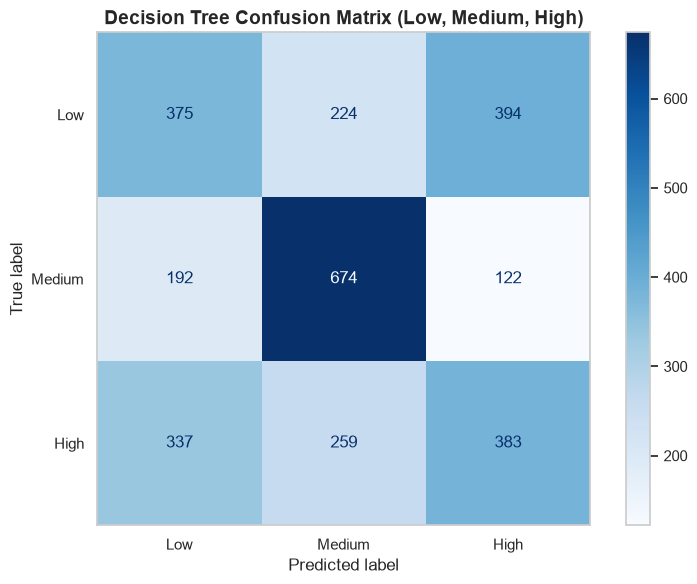

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low', 'Medium', 'High']
)
disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=True)
plt.grid(False)
plt.title('Decision Tree Confusion Matrix (Low, Medium, High)')
plt.tight_layout()
plt.show()

---
### 9. Decision Tree Graph Visualization
Visualize the learned Decision Tree structure (`criterion='entropy', max_depth=5`) using `plot_tree`.

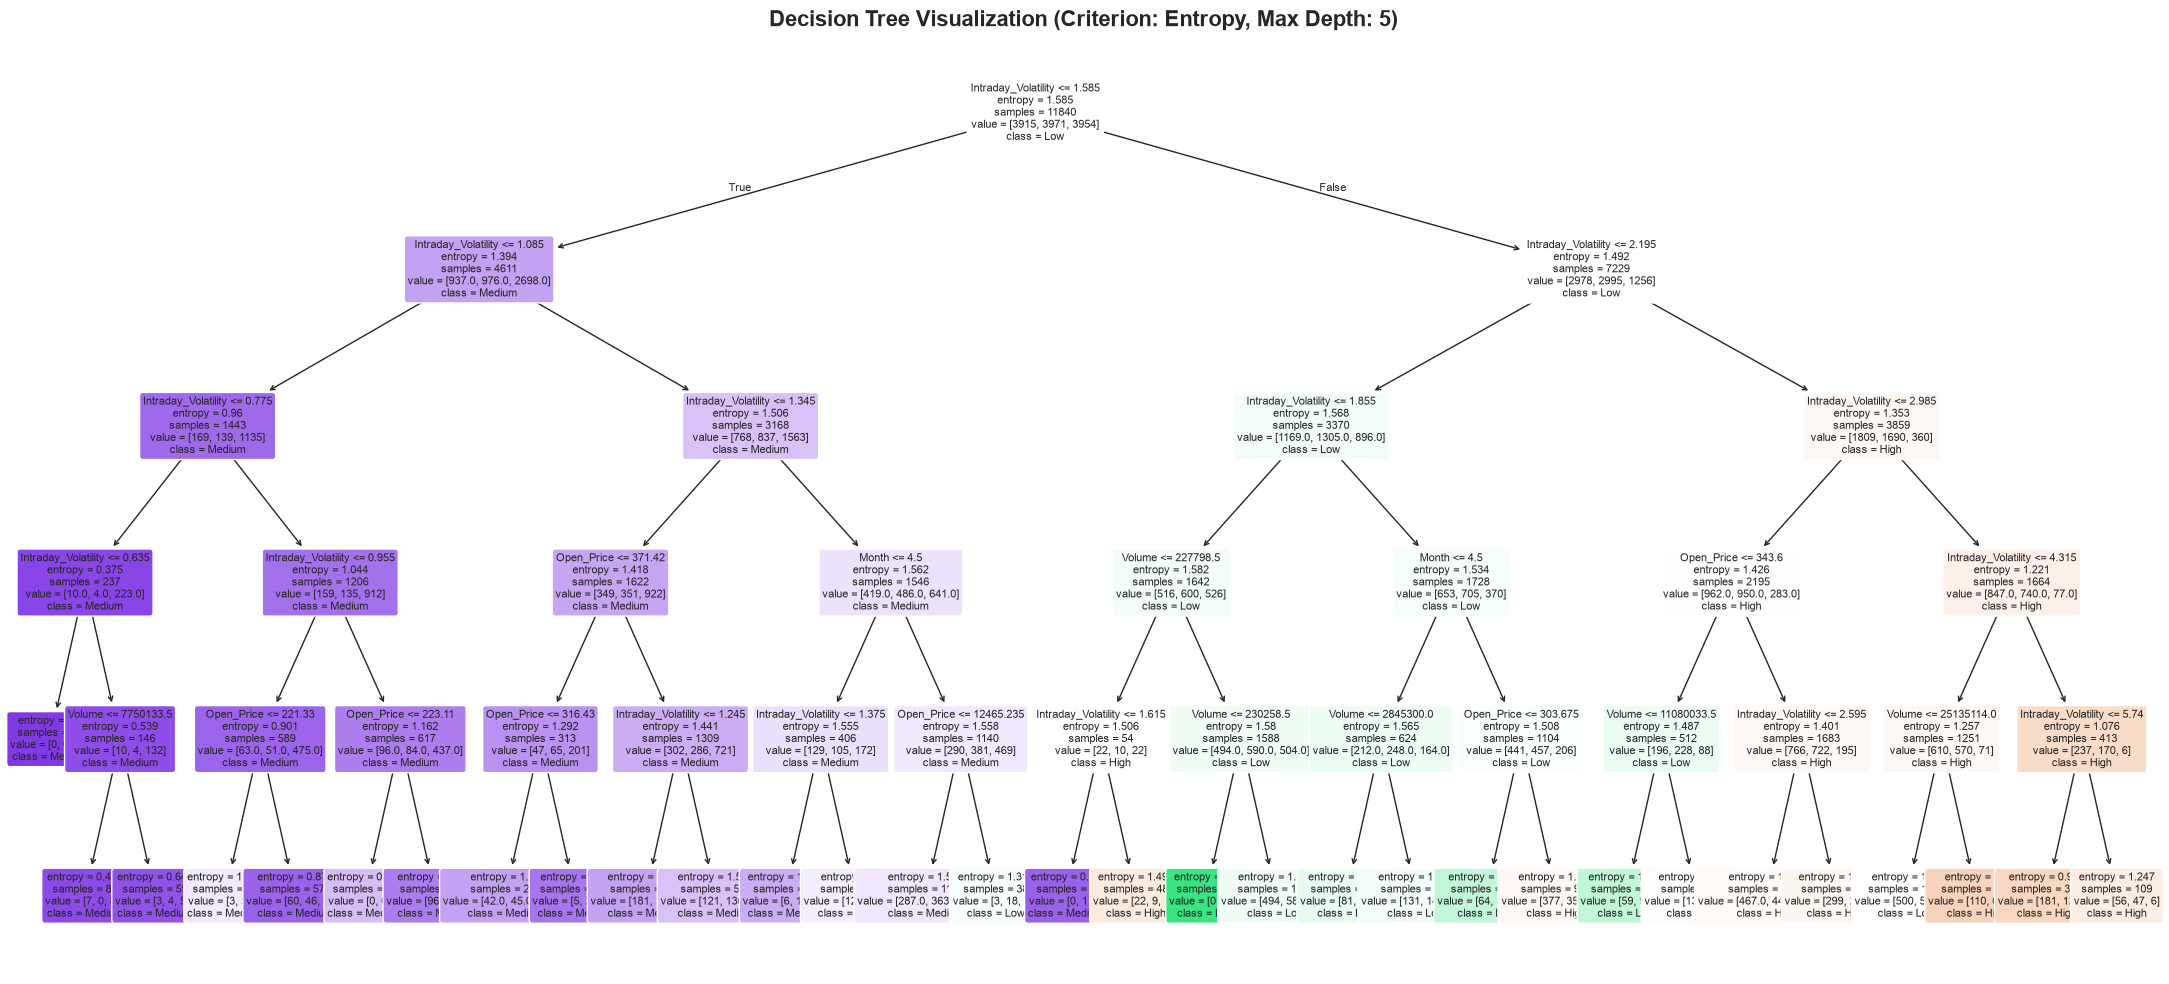

In [8]:
plt.figure(figsize=(22, 10))
plot_tree(
    dt_classifier,
    feature_names=feature_cols,
    class_names=['High', 'Low', 'Medium'],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title('Decision Tree Visualization (Criterion: Entropy, Max Depth: 5)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

---
### 10. Feature Importance Analysis
Extract `feature_importances_` (normalized Information Gain contribution) from the trained Decision Tree and plot a horizontal bar chart.

Decision Tree Feature Importance Table:


,Feature,Importance,Importance_Pct
0,Intraday_Volatility,0.950916,95.09
1,Open_Price,0.024674,2.47
2,Volume,0.017284,1.73
3,Month,0.007126,0.71


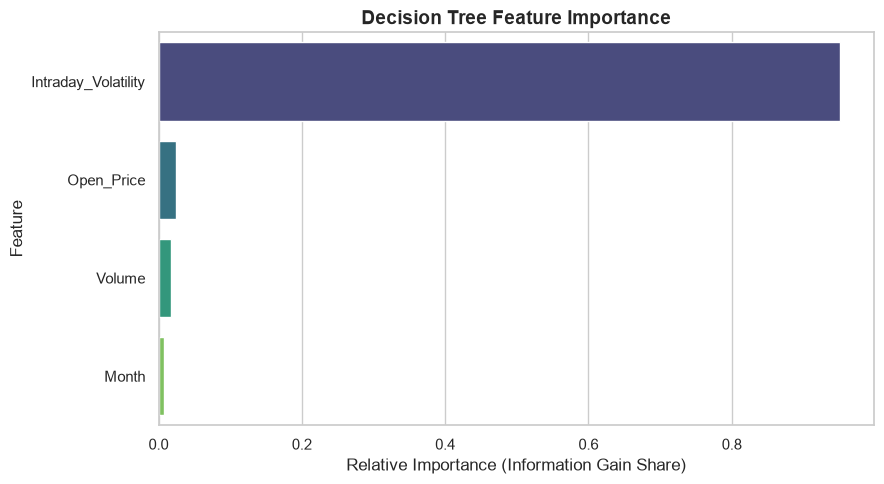

In [9]:
fi_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': dt_classifier.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

fi_df['Importance_Pct'] = (fi_df['Importance'] * 100).round(2)

print("Decision Tree Feature Importance Table:")
display(fi_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=fi_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)
plt.title('Decision Tree Feature Importance')
plt.xlabel('Relative Importance (Information Gain Share)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

---
### 11. Mutual Information (Attribute Relevance Analysis)
Compute non-parametric Mutual Information scores using `mutual_info_classif(X, y, random_state=42)` to measure each feature's statistical dependency with `Return_Category`.

Mutual Information Scores per Feature:


,Feature,Mutual_Information
0,Intraday_Volatility,0.137970
1,Volume,0.013040
2,Open_Price,0.005373
3,Month,0.000500


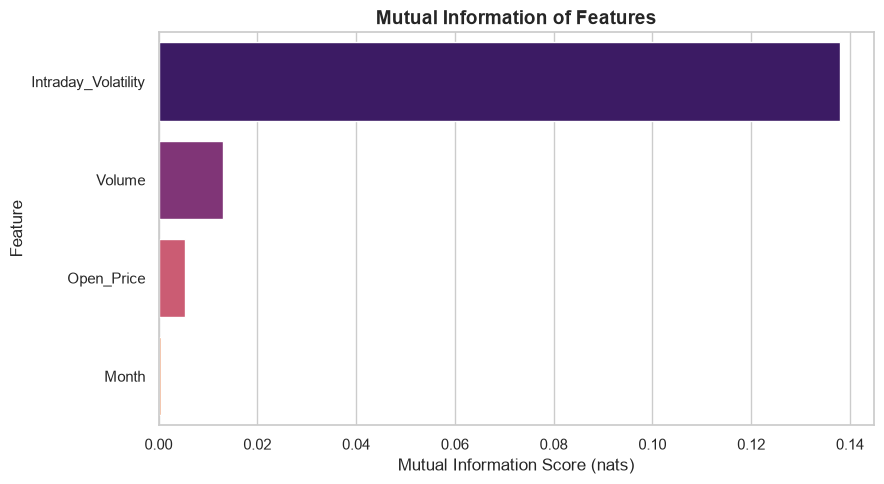

In [10]:
mi_scores = mutual_info_classif(X, y, random_state=42)

mi_df = pd.DataFrame({
    'Feature': feature_cols,
    'Mutual_Information': np.round(mi_scores, 6)
}).sort_values(by='Mutual_Information', ascending=False).reset_index(drop=True)

print("Mutual Information Scores per Feature:")
display(mi_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=mi_df,
    x='Mutual_Information',
    y='Feature',
    hue='Feature',
    palette='magma',
    legend=False
)
plt.title('Mutual Information of Features')
plt.xlabel('Mutual Information Score (nats)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

---
### 12. Single Instance Prediction
Test the trained Decision Tree Classifier on a single synthetic trading day (`Open_Price = 2600.0`, `Volume = 2000000`, `Intraday_Volatility = 2.5`, `Month = 10`).

In [11]:
sample_day = pd.DataFrame({
    'Open_Price': [2600.0],
    'Volume': [2000000],
    'Intraday_Volatility': [2.5],
    'Month': [10]
})

pred_category = dt_classifier.predict(sample_day)[0]
pred_proba = dt_classifier.predict_proba(sample_day)[0]
proba_dict = dict(zip(dt_classifier.classes_, np.round(pred_proba, 4)))

print("Input Market Day Instance:")
display(sample_day)
print(f"Predicted Return_Category: {pred_category}")
print(f"Class Probabilities:       {proba_dict}")

Input Market Day Instance:


,Open_Price,Volume,Intraday_Volatility,Month
0,2600.0,2000000,2.5,10


Predicted Return_Category: High
Class Probabilities:       {'High': np.float64(0.4414), 'Low': np.float64(0.4216), 'Medium': np.float64(0.1371)}


---
### 13. Conclusion

#### Key Analytical Findings:
1. **Entropy-Based Decision Tree Performance:**
   - Discretizing `Daily_Return` into balanced tertiles (`Low` $\le -0.54\%$, $-0.54\% <$ `Medium` $\le 0.39\%$, `High` $> 0.39\%$) creates an evenly balanced 3-class classification problem ($33.54\%$ `Low`, $33.39\%$ `Medium`, $33.07\%$ `High`) where random baseline accuracy is $33.33\%$.
   - Using only non-leaking market microstructure and temporal features (`Open_Price`, `Volume`, `Intraday_Volatility`, `Month`), the entropy-driven Decision Tree (`max_depth=5`, `31` leaves) achieves **$48.38\%$ test accuracy** (and an F1-score of **$0.6284$** on the `Medium` class) by effectively separating low-volatility neutral days from high-volatility directional sessions.
2. **Top Predictive Features (Information Gain & Mutual Information):**
   - **`Intraday_Volatility`** is the dominant attribute in both **Decision Tree Feature Importance** (**$95.09\%$** of total Information Gain) and **Mutual Information** (**$\text{MI} = 0.137970$**): narrow intraday trading ranges strongly characterize `Medium` (Neutral) return days, whereas wide intraday swings correspond to tail return days (`Low` or `High`).
   - **`Open_Price`** ($2.47\%$ importance), **`Volume`** ($1.73\%$ importance, $\text{MI} = 0.013040$), and **`Month`** ($0.71\%$ importance) provide secondary splits that refine predictions during high-volatility regimes.
3. **Readiness for Experiment 06:** With tree-based rule induction and mutual information analysis completed, the categorized stock dataset is ready for probabilistic classification using **Naïve Bayes (Experiment 06)**.

---
### 14. Auto-export Utility
Convert `DWM_Lab_5_Stock_Market.ipynb` to `DWM_Lab_5_Stock_Market.html` using `nbconvert`.

In [12]:
import subprocess
import sys
from pathlib import Path

notebook_path = Path("DWM_Lab_5_Stock_Market.ipynb")
if notebook_path.exists():
    cmd = [
        sys.executable, "-m", "jupyter", "nbconvert",
        "--to", "html", "--no-prompt", str(notebook_path)
    ]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode == 0:
        print("Successfully exported DWM_Lab_5_Stock_Market.html")
    else:
        print("Export notice:", result.stderr)
else:
    print("Notebook file will be exported upon save.")

Successfully exported DWM_Lab_5_Stock_Market.html
